# 04 — Renovação

**Pergunta de negócio.** Na renovação de cada grupo, quanto reajustar a taxa, e quanto confiar na experiência
do próprio grupo em vez da taxa manual?

**1. Pooling.** Nível de pooling do grupo $g$, com $\bar C_g$ o capital médio das vidas ativas e $R$ a retenção:

$$P_g = \min\!\left(R,\ \max(\text{piso},\ 3\,\bar C_g)\right).$$

Sinistros acima de $P_g$ saem da experiência do grupo; o excesso esperado, $\sum_v q_v m_v \max(C_v - P_g, 0)$,
vira encargo de pooling.

**2. Experiência contra a taxa manual**, em valor limitado ao pooling ($m_v$: fator da taxa manual):

$$
A/E_g = \frac{\sum \min(\text{sinistro}, P_g) + \text{IBNR}_g}{\sum_v q_v\, t_v\, m_v \min(C_v, P_g)}.
$$

**3. IBNR.** Padrão de aviso da carteira por chain ladder mensal; por grupo, estilo Bornhuetter-Ferguson:
$\text{IBNR}_g = \sum_{\text{meses}} E^{a\,priori}_{g,m}\,\big(1 - p(\text{idade}_m)\big)$, com $p$ a proporção avisada.

**4. Credibilidade** $Z_g$, por dois métodos:
- **mercado** (flutuação limitada, regra da raiz em vidas-ano $n_g$): $Z_g = \min\!\left(1, \sqrt{n_g / n_{plena}}\right)$, zero abaixo do mínimo;
- **Bühlmann-Straub**, com peso $w_g = n_{ef,g}$: $Z_g = \dfrac{w_g}{w_g + k}$, $\ k = \dfrac{s^2}{a}$ (variância dentro ÷ variância entre grupos, estimadas nos dados).

**5. Reajuste.** Com $\text{Custo}_g$ o custo limitado na manual sobre o censo atual (idades atualizadas):

$$
\text{prêmio puro}_g = \text{Custo}_g \times \big[Z_g\, A/E_g + (1 - Z_g)\big] + \text{encargo de pooling}_g,
\qquad
\text{taxa comercial} = \frac{\text{taxa pura}}{1 - \text{carregamento}}.
$$

O reajuste é taxa comercial ÷ taxa vigente − 1, com piso e teto, comparado com a regra contratual por faixa de
sinistralidade. Parâmetros em `config/renovacao.yaml` (carregamento, piso, teto e retenção são ilustrativos).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")   # informado explicitamente no notebook 03b
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, renovacao as R, backtest as B
from vgpricing.glmm import r_disponivel

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cr = (carregar_config(n, RAIZ) for n in ("base", "manual", "renovacao"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder, "Tábua oficial não carregada"
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros", "premios")}
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")      # gerada no notebook 03b
REF = pd.Timestamp(cfg["data_referencia"])
ren = R.renovar_carteira(dados, tabua, tabela, cr, REF)
xp, P = ren["experiencia"], ren["pooling"]
pd.Series({"A/E a priori contra a manual (contagem)": ren["ae_apriori"][0],
           "A/E a priori contra a manual (valor limitado)": ren["ae_apriori"][1],
           "nível de pooling mediano (R$)": P.median(),
           "parcela do custo esperado acima do pooling": xp["V_excesso"].sum() / (xp["V_manual"].sum() + xp["V_excesso"].sum()),
           "parcela dos sinistros que saiu da experiência": 1 - xp["V"].sum() / xp["V_total"].sum()}).to_frame("carteira")

,carteira
A/E a priori contra a manual (contagem),1.0083
A/E a priori contra a manual (valor limitado),1.0029
nível de pooling mediano (R$),"185,526.9770"
parcela do custo esperado acima do pooling,0.0305
parcela dos sinistros que saiu da experiência,0.0373


## 1. IBNR

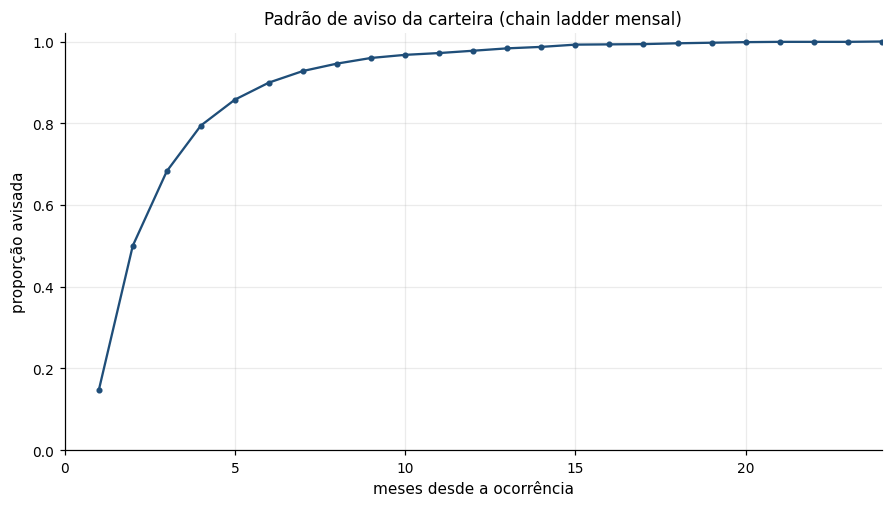

,N,IBNR_n,V,IBNR_v
início do ano-apólice,,,,
2020,159.0000,0.0000,"8,027,682.0414",0.0000
2021,303.0000,0.0000,"17,682,278.5316",0.0000
2022,454.0000,0.0000,"30,626,577.0061",0.0000
2023,484.0000,0.4676,"32,085,439.4026","20,800.6853"
2024,540.0000,18.3958,"39,407,202.3605","1,030,498.0080"
2025,217.0000,93.8721,"17,113,859.2693","6,374,251.8974"
total,"2,157.0000",112.7356,"144,943,038.6115","7,425,550.5906"


In [2]:
pn = ren["padrao_contagem"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pn["idade_meses"], pn["proporcao_avisada"], marker="o", ms=3, color="#1f4e79")
ax.set_xlim(0, 24); ax.set_ylim(0, 1.02); ax.set_xlabel("meses desde a ocorrência"); ax.set_ylabel("proporção avisada")
ax.set_title("Padrão de aviso da carteira (chain ladder mensal)"); plt.show()
ib = xp.groupby(xp["inicio_ano"].dt.year)[["N", "IBNR_n", "V", "IBNR_v"]].sum().rename_axis("início do ano-apólice")
ib.loc["total"] = ib.sum()
ib

A regra contratual usa IBNR fixo de 15% do prêmio, independentemente da idade da experiência. Aqui o IBNR
depende de quanto tempo passou desde cada mês de exposição.

## 2. Credibilidade

In [3]:
bs = ren["bs"]
pd.Series({"s² (variância dentro)": bs["s2"], "a (variância entre grupos)": bs["a"], "k = s²/a": bs["k"],
           "A/E médio da carteira": bs["media_carteira"]}).to_frame("Bühlmann-Straub")

,Bühlmann-Straub
s² (variância dentro),1.0562
a (variância entre grupos),0.0612
k = s²/a,17.2465
A/E médio da carteira,1.0436


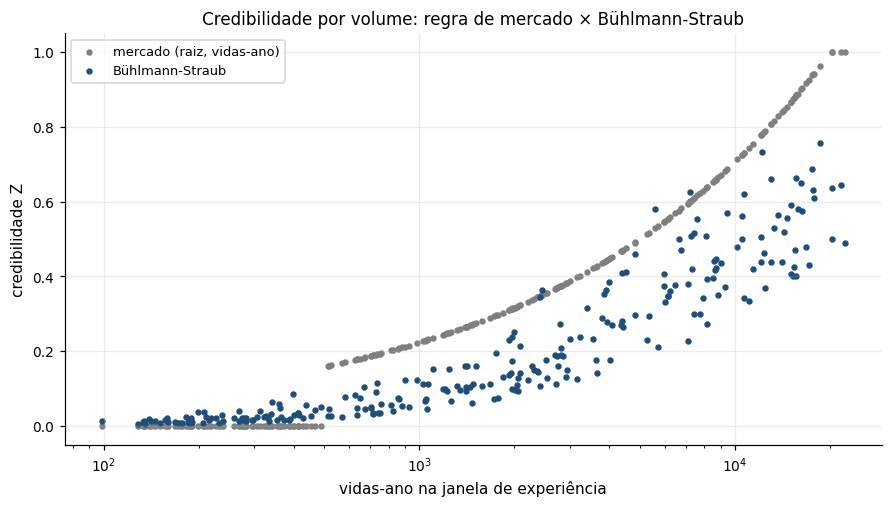

In [4]:
f = ren["fatores"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(f["vidas_ano"], f["Z_mercado"], s=10, label="mercado (raiz, vidas-ano)", color="#7f7f7f")
ax.scatter(f["vidas_ano"], f["Z_bs"], s=10, label="Bühlmann-Straub", color="#1f4e79")
ax.set_xscale("log"); ax.set_xlabel("vidas-ano na janela de experiência"); ax.set_ylabel("credibilidade Z"); ax.legend()
ax.set_title("Credibilidade por volume: regra de mercado × Bühlmann-Straub")
plt.show()

- Para o mesmo número de vidas-ano, o Bühlmann-Straub dá credibilidades diferentes conforme a concentração de
  capital (o peso é $n_{ef}$); a regra de mercado só olha vidas-ano.
- Com os limiares de mercado (plena em 20 mil vidas-ano), a regra da raiz dá **mais** credibilidade que a
  estimada nos dados. No levantamento da SOA com seguradoras de grupo, uma delas relatou o mesmo ao testar a
  própria fórmula com dados históricos.

## 3. Reajuste técnico × regra contratual

In [5]:
rj = ren["reajustes"]
display(pd.DataFrame({"reajuste técnico (aplicado)": rj["reajuste_aplicado"].describe(),
                      "regra contratual": rj["reajuste_regra"].describe()}))
pd.crosstab(pd.cut(rj["reajuste_aplicado"], [-1, -0.05, 0.05, 0.2, 1], labels=["redução", "estável", "até 20%", "acima de 20%"]),
            rj["reajuste_regra"], margins=True)

,reajuste técnico (aplicado),regra contratual
count,250.0000,250.0000
mean,-0.0642,0.0422
std,0.1159,0.0664
min,-0.1500,0.0000
25%,-0.1500,0.0000
50%,-0.1189,0.0000
75%,-0.0055,0.1500
max,0.3825,0.1500


reajuste_regra,0.0000,0.1000,0.1500,All
reajuste_aplicado,,,,
redução,117,8,42,167
estável,33,0,13,46
até 20%,17,0,8,25
acima de 20%,10,0,2,12
All,177,8,65,250


A regra contratual só aumenta, olha só o último ano, usa IBNR fixo e não distingue um grupo de 50 vidas de
um de 5 mil. Quando aplicada por anos seguidos, acumula aumentos mesmo quando a sinistralidade alta foi sorte;
por isso a taxa técnica sai abaixo da vigente em muitos grupos desta carteira, e o piso limita a redução. O
reajuste técnico recalcula a taxa manual sobre as idades atuais e dá a cada grupo a credibilidade que o volume
dele justifica. A decisão comercial continua sendo da área; o reajuste técnico é o ponto de partida.

## 4. Backtest fora do tempo: qual credibilidade usar?

Cada grupo é renovado no início do seu último ano-apólice maduro (encerrado há mais de 12 meses), usando só o
que se sabia na véspera: experiência e IBNR naquela data, **taxa manual reestimada só com dados anteriores** e
$k$ estimado na carteira da data mais antiga. Depois compara-se com o que aconteceu. Métrica principal: deviance
de Poisson nos óbitos do ano-alvo, com intervalo de 95% por bootstrap pareado (reamostrando grupos) para a
diferença em relação à taxa manual pura.

In [6]:
assert r_disponivel(), "o backtest reestima a taxa manual no R"
alvo = B.anos_alvo(dados["estipulantes"], REF, cr["backtest"]["meses_maturacao_alvo"])
cel0, info0 = M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua, alvo["inicio_ano"].min(), cm)
# o backtest reestima a taxa manual com o MESMO método escolhido no notebook 03b, só com dados anteriores
metodo = tabela["meta"]["modelo_escolhido"]
prioris = M.carregar_tabela(RAIZ / "artefatos/prioris_soa.yaml")
tabela0 = M.ajustar_tabela(cel0, metodo, cm, prioris, info0)
bt = B.executar(dados, tabua, tabela0, cr, REF)
print(f"{len(alvo)} grupos | renovações entre {alvo['inicio_ano'].min().date()} e {alvo['inicio_ano'].max().date()} | "
      f"taxa manual do backtest ({metodo}) com {info0['obitos']} óbitos (dados até {info0['corte_experiencia']})")
display(bt["resumo"])
bt["comparacao_deviance"]

250 grupos | renovações entre 2023-02-01 e 2024-01-01 | taxa manual do backtest (ridge com priori SOA) com 360 óbitos (dados até 2022-02-01)


,método,deviance (contagem),erro relativo (valor limitado),previsto/observado (valor limitado),S/P carteira,dispersão da S/P entre grupos
0,Só taxa manual (Z = 0),316.0315,0.0607,1.0405,0.6238,0.6119
1,"Credibilidade de mercado (raiz, vidas-ano)",325.5420,0.0707,1.0389,0.6247,0.6348
2,Bühlmann-Straub (n efetivo),321.9686,0.0699,1.0341,0.6276,0.6281
3,Só experiência (Z = 1),427.2547,0.0946,1.0566,0.6146,0.9850
4,Regra contratual 75/85% (prêmio efetivamente c...,NaN,NaN,NaN,0.5434,0.5435


,método,deviance,diferença vs só manual,IC95 inf,IC95 sup
0,Só taxa manual (Z = 0),316.0315,0.0000,0.0000,0.0000
1,"Credibilidade de mercado (raiz, vidas-ano)",325.5420,9.5105,-7.4629,26.2415
2,Bühlmann-Straub (n efetivo),321.9686,5.9371,-11.4980,22.5531
3,Só experiência (Z = 1),427.2547,111.2233,46.8588,175.6452


**Leitura.** "Só experiência" é significativamente pior que a manual. As duas credibilidades não se distinguem
da manual, nem entre si, com significância: os intervalos da diferença contêm zero. Com menos de um óbito
esperado por grupo no ano-alvo, um único ano realizado é dominado pelo sorteio de quem morreu, e a taxa manual
do backtest é fraca (poucos dados anteriores à primeira renovação). É o que acontece num backtest real com
pouco volume; por isso a métrica tem intervalo, e a Etapa 6 empilha vários anos-alvo para ganhar poder.

No notebook `90_validacao_sintetica`, as mesmas previsões são comparadas com o custo **esperado** verdadeiro do
gerador (sem o sorteio): lá as duas credibilidades ficam claramente à frente da manual, da experiência pura e da
regra contratual.

## 5. Decisão e limitações

**Decisão provisória (até a Etapa 6):** Bühlmann-Straub com peso $n_{ef}$. Empata com a regra de mercado neste
teste, mas o $k$ sai dos dados (não de limiares escolhidos à mão) e o peso pune a concentração de capital. A regra
de mercado fica calculada ao lado, como referência para a área comercial.

**Limitações:**
- Um ano-alvo não tem poder para separar os métodos neste volume.
- O $k$ é estimado sem incerteza; com poucos óbitos por grupo, ela é grande. A sensibilidade do reajuste ao $k$ entra na etapa de validação.
- O IBNR por grupo supõe exposição uniforme dentro do ano-apólice.
- Carregamento, piso, teto e retenção são ilustrativos; devem vir da nota técnica e da política da seguradora.
- A regra contratual de referência é a de uma apólice pública; cada contrato tem a sua.